In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure notebook plots
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# Load the email dataset
email_data = pd.read_csv("emails.csv", index_col=0)

# Preview the data
email_data.head()

,id,subject,email,label
4282,4282,Subject: RE: [ILUG] Dell GX260 V Redhat 7.3\r\n,> When I get a box I don't want any of that in...,0
6293,6293,Subject: IBM eNews: Aktuelle Informationen von...,IBM eNews\r\n 4. Juli 2002\r\n \r\n Liebe Lese...,0
2349,2349,"Subject: [zzzzteana] Height, weight, girth, et...","http://www.guardian.co.uk/uk_news/story/0,3604...",0
3786,3786,Subject: Re: The GOv gets tough on Net Users.....,Hire a really talented skywriter to doodle nud...,0
4731,4731,Subject: Lander risks missing Mars trip\r\n,"URL: http://www.newsisfree.com/click/-4,805285...",0


In [3]:
# Convert email subjects and bodies to lowercase
email_data["subject"] = email_data["subject"].str.lower()
email_data["email"] = email_data["email"].str.lower()

In [4]:
# Count missing values in each column
email_data.isna().sum()

id         0
subject    6
email      0
label      0
dtype: int64

In [5]:
# Replace missing text with an empty string
email_data[["subject", "email"]] = (
    email_data[["subject", "email"]]
    .fillna("")
)

# Verify that no missing values remain
email_data.isna().sum()

id         0
subject    0
email      0
label      0
dtype: int64

In [6]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
train, test = train_test_split(
    email_data,
    test_size=0.20,
    random_state=0,
    stratify=email_data["label"]
)

print(f"Training observations: {len(train)}")
print(f"Test observations: {len(test)}")

Training observations: 6010
Test observations: 1503


In [7]:
# Compare the proportion of spam emails
print(
    f"Overall spam proportion: "
    f"{email_data['label'].mean():.1%}"
)

print(
    f"Training spam proportion: "
    f"{train['label'].mean():.1%}"
)

print(
    f"Test spam proportion: "
    f"{test['label'].mean():.1%}"
)

Overall spam proportion: 25.6%
Training spam proportion: 25.6%
Test spam proportion: 25.6%


## Question 1

In [8]:
# Question 1a
example_index = 1

not_spam_example = (
    train.loc[
        train["label"] == 0,
        "email"
    ]
    .iloc[example_index]
)

spam_example = (
    train.loc[
        train["label"] == 1,
        "email"
    ]
    .iloc[example_index]
)

print("--------")
print("NOT SPAM")
print("--------")
print(not_spam_example)

print("\n----")
print("SPAM")
print("----")
print(spam_example)

--------
NOT SPAM
--------
on saturday, september 28, 2002, at 12:54 pm, gary lawrence murphy 
 wrote:
 
 > although it's like a total shock to 99.999% (5nines) of all the
 > employed website designers out there, the truth is webforms /can/
 > accept "u.s. of a" as a country.  incredible, but true.  web forms can
 > also accept /multiple/ or even /free-form/ telephone numbers and can
 > even be partitioned into manageable steps. all this can also be done
 > without selling exclusive rights to your wallet to the world's
 > second-richest corporation (assuming cisco is still #1) and vendor
 > locking your business into their "small transaction fee" tithe.
 
 yes, but this is what normally happened:
 
 engineer: we can put an input validator/parser on the backend to do 
 that.
 
 designer: there's a javascript library that can do some of the 
 pre-validation.
 
 creative director: i want it in blue, with a zooming logo.
 
 engineer: can we get to that later, we need to meet functional spe

**Q1a: Your answer:** 

The spam email is encoded (it is made of a long string of more or less unreadable strings). It also seems to be written in what seems like an eatsern european language.

In [9]:
# Question 1b
def word_detector(words, texts):
    """Return binary indicators showing whether each word appears in each text."""
    results = pd.DataFrame(index=texts.index)

    for word in words:
        results[word] = texts.str.contains(
            word,
            case=False,
            na=False,
            regex=False
        ).astype(int)

    return results

In [10]:
# Test the function on a small example
word_detector(
    ["hello", "bye", "world"],
    pd.Series([
        "hello",
        "hello worldhello"
    ])
)

,hello,bye,world
0,1,0,0
1,1,0,1


In [11]:
# Verification - do not modify

word_detector_check = word_detector(
    ["hello", "bye", "world"],
    train["email"]
)

print(
    "Q1b Answer - Correct number of rows:",
    len(word_detector_check) == len(train)
)

print(
    "Correct columns:",
    word_detector_check.columns.tolist()
    == ["hello", "bye", "world"]
)

print(
    "Index preserved:",
    word_detector_check.index.equals(
        train.index
    )
)

print(
    "Only binary values:",
    word_detector_check
    .isin([0, 1])
    .all()
    .all()
)

Q1b Answer - Correct number of rows: True
Correct columns: True
Index preserved: True
Only binary values: True


In [12]:
# Question 1c

candidate_words = [
    "offer", "free", "urgent", "limited", "winner", "congratulation"
]

# using the word detector
word_features = word_detector(
    candidate_words,
    train["email"]
)

# Create
comparison = pd.DataFrame(
    word_features,
    columns=candidate_words,
    index=train.index
).groupby(train["label"]).mean().T

comparison.columns = ["Non-spam", "Spam"]

comparison

,Non-spam,Spam
offer,0.061759,0.310188
free,0.280823,0.489293
urgent,0.005370,0.027904
limited,0.024166,0.101882
winner,0.009174,0.014925
congratulation,0.002685,0.018819


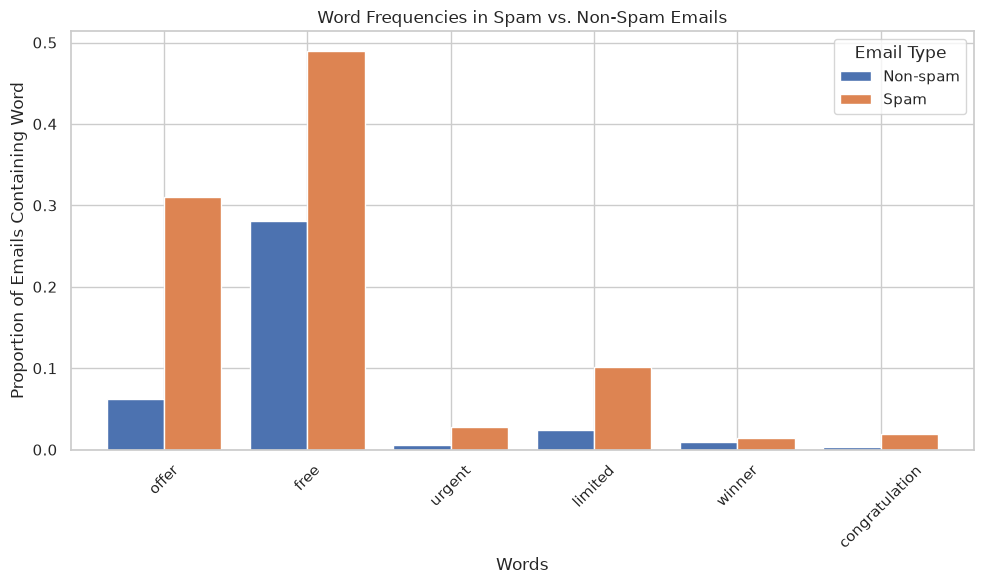

In [13]:
comparison.plot(kind="bar", figsize=(10, 6), width=0.8)

plt.title("Word Frequencies in Spam vs. Non-Spam Emails")
plt.xlabel("Words")
plt.ylabel("Proportion of Emails Containing Word")
plt.xticks(rotation=45)
plt.legend(title="Email Type")
plt.tight_layout()
plt.show()

## Question 2

In [14]:
# Question 2a

model_words = [
    "drug",
    "bank",
    "prescription",
    "memo",
    "private"
]

# Create binary word features for the training emails
X_train = word_detector(
    model_words,
    train["email"]
)

# Select the corresponding target labels
y_train = train["label"].copy()

In [15]:
X_train.head()

,drug,bank,prescription,memo,private
639,0,0,0,0,0
3120,0,0,0,0,0
4771,0,0,0,0,0
2556,0,0,0,0,0
3426,0,0,0,0,0


In [16]:
y_train.head()

639     0
3120    1
4771    0
2556    0
3426    0
Name: label, dtype: int64

In [17]:
# Verification - do not modify

print(
    "Q2a Answer - Number of training observations:",
    len(X_train)
)

print(
    "Predictors and target have equal length:",
    len(X_train) == len(y_train)
)

print(
    "Correct predictor columns:",
    X_train.columns.tolist() == model_words
)

print(
    "Target contains only 0 and 1:",
    set(y_train.unique()).issubset({0, 1})
)

Q2a Answer - Number of training observations: 6010
Predictors and target have equal length: True
Correct predictor columns: True
Target contains only 0 and 1: True


In [18]:
from sklearn.linear_model import LogisticRegression

# Question 2b

# Create the logistic regression classifier
spam_model = LogisticRegression()

# Fit the classifier using the training features and labels
spam_model.fit(X_train, y_train)

# Predict the class for each training email
y_train_predicted = spam_model.predict(X_train)

# Predict the probability that each training email is spam
y_train_probability = spam_model.predict_proba(X_train)[:,1]

In [19]:
# Verification - do not modify

print(
    "Q2b Answer - Model fitted:",
    hasattr(spam_model, "classes_")
)

print(
    "Number of class predictions:",
    len(y_train_predicted)
)

print(
    "Number of probability predictions:",
    len(y_train_probability)
)

print(
    "All probabilities between 0 and 1:",
    (
        (y_train_probability >= 0)
        & (y_train_probability <= 1)
    ).all()
)

Q2b Answer - Model fitted: True
Number of class predictions: 6010
Number of probability predictions: 6010
All probabilities between 0 and 1: True


In [20]:
# Check the order of the classes
spam_model.classes_

array([0, 1])

In [21]:
# Display the first five probability predictions
spam_model.predict_proba(X_train)[:5]

array([[0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275]])

In [22]:
# Inspect the first ten spam probabilities
y_train_probability[:10]

array([0.23553275, 0.23553275, 0.23553275, 0.23553275, 0.23553275,
       0.23553275, 0.23553275, 0.23553275, 0.23553275, 0.23553275])

In [23]:
# Question 2c

# Create the six-word feature matrix using the words
# selected in Question 1c.
X_train_candidate = word_detector(
    candidate_words,
    train["email"]
)

# Create a logistic regression classifier
candidate_model = LogisticRegression()

# Fit the model using the training data
candidate_model.fit(X_train_candidate, y_train)

# Generate class predictions
y_train_candidate_predicted = candidate_model.predict(X_train_candidate)

# Generate predicted probabilities for spam
y_train_candidate_probability = candidate_model.predict_proba(X_train_candidate)[:,1]

In [24]:
# Verification - do not modify

print(
    "Q2c Answer - Correct number of observations:",
    len(X_train_candidate) == len(y_train)
)

print(
    "Six predictors used:",
    X_train_candidate.shape[1] == 6
)

print(
    "Candidate model fitted:",
    hasattr(candidate_model, "classes_")
)

print(
    "All probabilities are valid:",
    (
        (y_train_candidate_probability >= 0)
        & (y_train_candidate_probability <= 1)
    ).all()
)

Q2c Answer - Correct number of observations: True
Six predictors used: True
Candidate model fitted: True
All probabilities are valid: True


## Question 3

In [25]:
from sklearn.metrics import accuracy_score

training_accuracy = accuracy_score(
    y_train,
    y_train_predicted
)

print(
    f"Training accuracy: "
    f"{training_accuracy:.3f}"
)

Training accuracy: 0.758


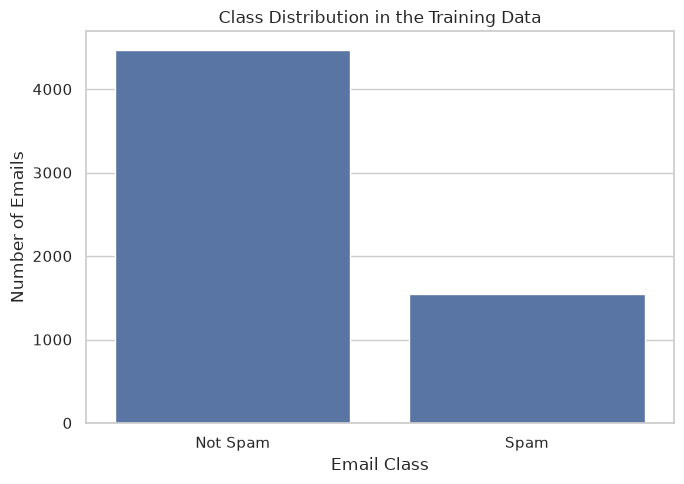

In [26]:
class_counts = (
    train["label"]
    .map({
        0: "Not Spam",
        1: "Spam"
    })
)

plt.figure(figsize=(7, 5))

sns.countplot(
    x=class_counts,
    order=["Not Spam", "Spam"]
)

plt.xlabel("Email Class")
plt.ylabel("Number of Emails")
plt.title("Class Distribution in the Training Data")

plt.tight_layout()
plt.show()

In [27]:
# Question 3a

# Create predictions that always predict the majority class (0 = not spam)
majority_predictions = np.zeros(len(y_train), dtype=int)

# Calculate the accuracy of the majority-class baseline
majority_accuracy = accuracy_score(y_train, majority_predictions)

print(
    f"Logistic regression accuracy: "
    f"{training_accuracy:.3f}"
)

print(
    f"Majority-class accuracy: "
    f"{majority_accuracy:.3f}"
)

Logistic regression accuracy: 0.758
Majority-class accuracy: 0.744


In [28]:
# Verification - do not modify

print(
    "Q3a Answer - Correct number of predictions:",
    len(majority_predictions) == len(y_train)
)

print(
    "Baseline predicts only class 0:",
    np.all(majority_predictions == 0)
)

Q3a Answer - Correct number of predictions: True
Baseline predicts only class 0: True


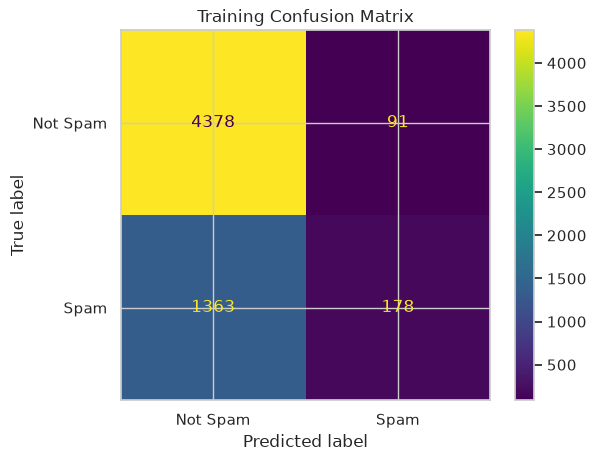

In [29]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Question 3b
# Calculate the confusion matrix
training_confusion_matrix = confusion_matrix(
    y_train,
    spam_model.predict(X_train)
)

# Create the confusion-matrix display
display = ConfusionMatrixDisplay(
    confusion_matrix=training_confusion_matrix,
    display_labels=[
        "Not Spam",
        "Spam"
    ]
)

# Display the confusion matrix
display.plot()

plt.title(
    "Training Confusion Matrix"
)

plt.show()

In [30]:
# Verification - do not modify

print(
    "Q3b Answer - Confusion matrix shape:",
    training_confusion_matrix.shape
)

print(
    "All training observations represented:",
    training_confusion_matrix.sum()
    == len(y_train)
)

Q3b Answer - Confusion matrix shape: (2, 2)
All training observations represented: True


In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Question 3c

# Calculate training accuracy
training_accuracy = accuracy_score(y_train, y_train_predicted)

# Calculate precision for the spam class
training_precision = precision_score(y_train, y_train_predicted, pos_label=1)

# Calculate recall for the spam class
training_recall = recall_score(y_train, y_train_predicted, pos_label=1)

# Calculate F1-score
training_f1 = f1_score(y_train, y_train_predicted, pos_label=1)

print(
    f"Accuracy:  {training_accuracy:.3f}"
)

print(
    f"Precision: {training_precision:.3f}"
)

print(
    f"Recall:    {training_recall:.3f}"
)

print(
    f"F1-score:  {training_f1:.3f}"
)

Accuracy:  0.758
Precision: 0.662
Recall:    0.116
F1-score:  0.197


## Question 4

In [32]:
# Question 4a

# Create predictions using a threshold of 0.30
predictions_030 = (y_train_probability >= 0.30).astype(int)

# Create predictions using a threshold of 0.50
predictions_050 = (y_train_probability >= 0.50).astype(int)

# Create predictions using a threshold of 0.70
predictions_070 = (y_train_probability >= 0.70).astype(int)

In [33]:
# Verification - do not modify

print(
    "Q4a Answer - Correct number of predictions:",
    len(predictions_030) == len(y_train)
    and len(predictions_050) == len(y_train)
    and len(predictions_070) == len(y_train)
)

print(
    "All predictions are binary:",
    set(np.unique(predictions_030)).issubset({0, 1})
    and set(np.unique(predictions_050)).issubset({0, 1})
    and set(np.unique(predictions_070)).issubset({0, 1})
)

Q4a Answer - Correct number of predictions: True
All predictions are binary: True


In [34]:
# 4b

threshold_results = pd.DataFrame({
    "threshold": [
        0.30,
        0.50,
        0.70
    ],
    "precision": [
        precision_score(y_train, predictions_030),
        precision_score(y_train, predictions_050),
        precision_score(y_train, predictions_070)
    ],
    "recall": [
        recall_score(y_train, predictions_030),
        recall_score(y_train, predictions_050),
        recall_score(y_train, predictions_070)
    ]
})

threshold_results

,threshold,precision,recall
0,0.3,0.565476,0.184945
1,0.5,0.661710,0.115509
2,0.7,0.800000,0.041531


**Your answer:** Increasing the threshold increase precision, but makes the recall smaller.

High classification threshold makes it less likely to flag non-spam email as spam at the cost of seeing more spam email in your mailbox. It could be used for people that are expecting very important emails and want to be sure to see it as soon as possible.

Low classification threshold makes it more likely to flag non-spam email as spam but will keep most spam out of the mailbox. It could be used by people that really don't want to see spam.

## Question 5

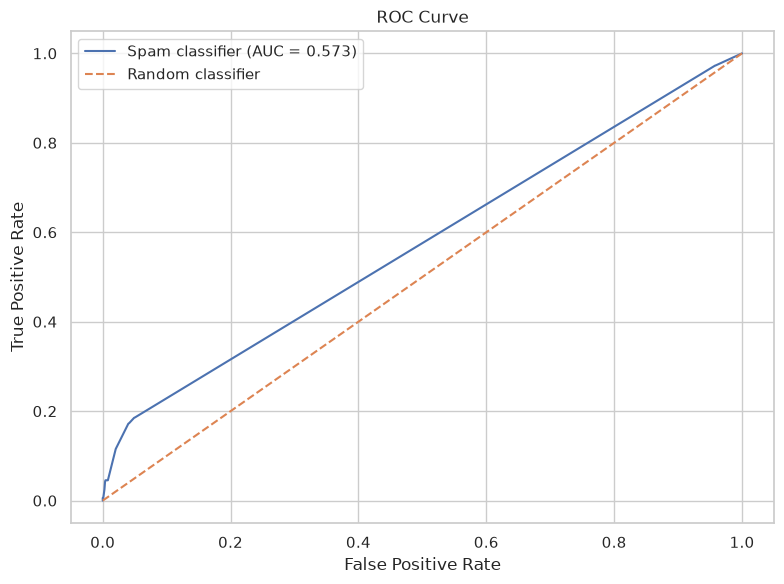

In [35]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Calculate the ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_train,
    y_train_probability
)

training_roc_auc = roc_auc_score(
    y_train,
    y_train_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Spam classifier (AUC = {training_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.tight_layout()
plt.show()

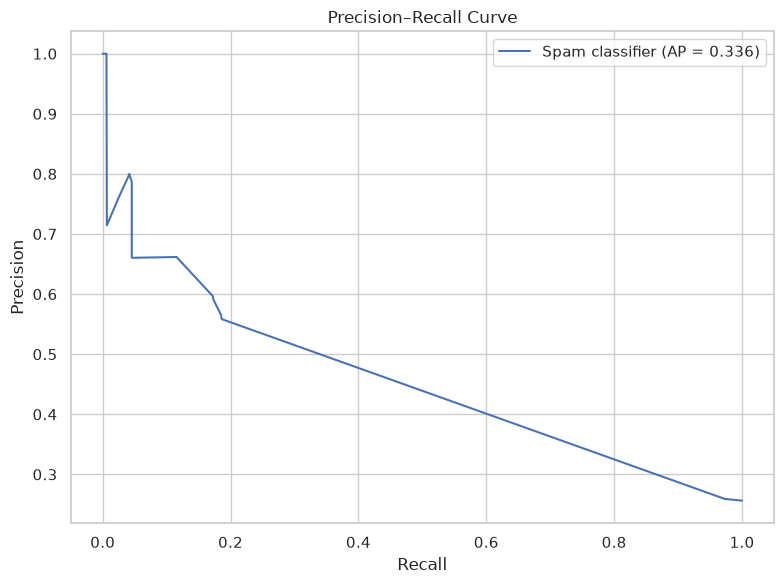

In [36]:
# Calculate precision and recall across thresholds
pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(
        y_train,
        y_train_probability
    )
)

training_average_precision = (
    average_precision_score(
        y_train,
        y_train_probability
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=(
        "Spam classifier "
        f"(AP = {training_average_precision:.3f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()

The ROC curve and the precision-recall curve indicate that our classifier is not good to distinguish between spam and none-spam. The AUC of 0.573 makes our model slightly better than a random coin flip (0.5), the low AP indicate that our model will have trouble differenciating the spam emails.

Like seen in previous questions, accuracy is not useful in an imbalanced dataset. The precision-recall curve is useful has it gives us information about the spam emails successfully classified as spam, which indicate the success of our indentifier better than accuracy. Increasing the threshold increase precision, but makes the recall smaller. It is another way of seeing how good our model is without accuracy

## Question 6

In [37]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Question 6

# Create a 5-fold stratified cross-validation object
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Define the evaluation metrics
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

# Evaluate the original five-word model
baseline_cv_results = cross_validate(
    spam_model,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring
)

# Evaluate the six-word candidate model
candidate_cv_results = cross_validate(
    candidate_model,
    X_train_candidate,
    y_train,
    cv=stratified_cv,
    scoring=scoring
)

# Create a DataFrame containing the mean
# cross-validation performance of both models
cv_comparison = pd.DataFrame({
    "spam_model": [
        baseline_cv_results["test_accuracy"].mean(),
        baseline_cv_results["test_precision"].mean(),
        baseline_cv_results["test_recall"].mean(),
        baseline_cv_results["test_f1"].mean(),
        baseline_cv_results["test_roc_auc"].mean()
    ],
    "candidate_model": [
        candidate_cv_results["test_accuracy"].mean(),
        candidate_cv_results["test_precision"].mean(),
        candidate_cv_results["test_recall"].mean(),
        candidate_cv_results["test_f1"].mean(),
        candidate_cv_results["test_roc_auc"].mean()
    ]
}, index=["accuracy", "precision", "recall", "f1", "roc_auc"])

cv_comparison.round(3)

,spam_model,candidate_model
accuracy,0.758,0.780
precision,0.665,0.648
recall,0.116,0.319
f1,0.197,0.426
roc_auc,0.573,0.687


**Your answer:** The candidate_model has higher metrics in everything except precision (where both model are comparable) especially the f1 and recall. 

candidate_model will be carried forward

In [38]:
# Select the feature set with the higher mean cross-validation F1-score

baseline_mean_f1 = baseline_cv_results["test_f1"].mean()
candidate_mean_f1 = candidate_cv_results["test_f1"].mean()

if candidate_mean_f1 > baseline_mean_f1:
    selected_words = candidate_words
else:
    selected_words = baseline_words

# Create the selected training feature matrix
X_train_selected = pd.DataFrame(
    word_detector(selected_words, train["email"]),
    columns=selected_words,
    index=train.index
)

y_train_selected = train["label"].copy()

print("Selected words:", selected_words)

Selected words: ['offer', 'free', 'urgent', 'limited', 'winner', 'congratulation']


In [39]:
# Verification - do not modify

print(
    "Q6 Answer - Both models evaluated with five folds:",
    len(baseline_cv_results["test_f1"]) == 5
    and len(candidate_cv_results["test_f1"]) == 5
)

print(
    "Selected feature set is valid:",
    selected_words in [
        model_words,
        candidate_words
    ]
)

Q6 Answer - Both models evaluated with five folds: True
Selected feature set is valid: True


## Question 7

In [40]:
from sklearn.model_selection import GridSearchCV

# Question 7

# Define the values of C to compare
parameter_grid = {
    "C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

# Create the grid search using logistic regression,
# F1-score, and the stratified cross-validation object
grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    parameter_grid,
    scoring="f1",
    cv=stratified_cv
)

# Fit the grid search using the selected training features
grid_search.fit(X_train_selected, y_train_selected)

# Report the best value of C
print(
    "Best C:",
    grid_search.best_params_["C"]
)

# Report the corresponding mean cross-validation F1-score
print(
    "Best mean CV F1-score:",
    grid_search.best_score_
)

Best C: 100
Best mean CV F1-score: 0.4274519242706159


In [41]:
# Verification - do not modify

print(
    "Q7 Answer - Best C is one of the candidates:",
    grid_search.best_params_["C"]
    in parameter_grid["C"]
)

print(
    "Best CV F1-score is valid:",
    0 <= grid_search.best_score_ <= 1
)

Q7 Answer - Best C is one of the candidates: True
Best CV F1-score is valid: True


## Question 8

In [42]:
# Question 8

# Get the best value of C from Question 7
best_c = grid_search.best_params_["C"]

# Create a standard tuned logistic regression model
tuned_model = LogisticRegression(
    C=best_c,
    max_iter=1000
)

# Create a tuned logistic regression model that
# accounts for class imbalance
balanced_model = LogisticRegression(
    C=best_c,
    class_weight="balanced",
    max_iter=1000
)

# Metrics used to compare the two models
comparison_scoring = [
    "precision",
    "recall",
    "f1"
]

# Evaluate the standard tuned model
tuned_cv = cross_validate(
    tuned_model,
    X_train_selected,
    y_train_selected,
    cv=stratified_cv,
    scoring=comparison_scoring
)

# Evaluate the balanced model
balanced_cv = cross_validate(
    balanced_model,
    X_train_selected,
    y_train_selected,
    cv=stratified_cv,
    scoring=comparison_scoring
)

# Create a table containing the mean CV results
model_comparison = pd.DataFrame(
    {
        "Tuned Logistic Regression": [
            tuned_cv["test_precision"].mean(),
            tuned_cv["test_recall"].mean(),
            tuned_cv["test_f1"].mean()
        ],
        "Balanced Logistic Regression": [
            balanced_cv["test_precision"].mean(),
            balanced_cv["test_recall"].mean(),
            balanced_cv["test_f1"].mean()
        ]
    },
    index=["Precision", "Recall", "F1-score"]
)

model_comparison.round(3)

,Tuned Logistic Regression,Balanced Logistic Regression
Precision,0.648,0.564
Recall,0.321,0.423
F1-score,0.427,0.466


In [43]:
# Select the final model using mean cross-validation F1-score

tuned_mean_f1 = tuned_cv["test_f1"].mean()

balanced_mean_f1 = balanced_cv["test_f1"].mean()

if balanced_mean_f1 > tuned_mean_f1:
    final_model = balanced_model
else:
    final_model = tuned_model

print(
    "Selected final model:",
    type(final_model).__name__
)

print(
    "Uses balanced class weights:",
    final_model.class_weight == "balanced"
)

Selected final model: LogisticRegression
Uses balanced class weights: True


## Question 9

In [46]:
# Question 9

# Create the test feature matrix using the same
# features selected during model development
X_test = pd.DataFrame(
    word_detector(selected_words, test["email"]),
    columns=selected_words,
    index=test.index
)

# Create the test target
y_test = test["label"].copy()

# Fit the selected final classifier using all selected training data
final_model.fit(X_train_selected, y_train_selected)

# Generate class predictions
y_test_predicted = final_model.predict(X_test)

# Generate predicted probabilities for the spam class
y_test_probability = final_model.predict_proba(X_test)[:, 1]

In [47]:
# Calculate final test metrics

test_accuracy = accuracy_score(y_test, y_test_predicted)

test_precision = precision_score(y_test, y_test_predicted)

test_recall = recall_score(y_test, y_test_predicted)

test_f1 = f1_score(y_test, y_test_predicted)

test_roc_auc = roc_auc_score(y_test, y_test_predicted)

print(
    f"Test accuracy:  {test_accuracy:.3f}"
)

print(
    f"Test precision: {test_precision:.3f}"
)

print(
    f"Test recall:    {test_recall:.3f}"
)

print(
    f"Test F1-score:  {test_f1:.3f}"
)

print(
    f"Test ROC-AUC:   {test_roc_auc:.3f}"
)

Test accuracy:  0.789
Test precision: 0.639
Test recall:    0.405
Test F1-score:  0.496
Test ROC-AUC:   0.663


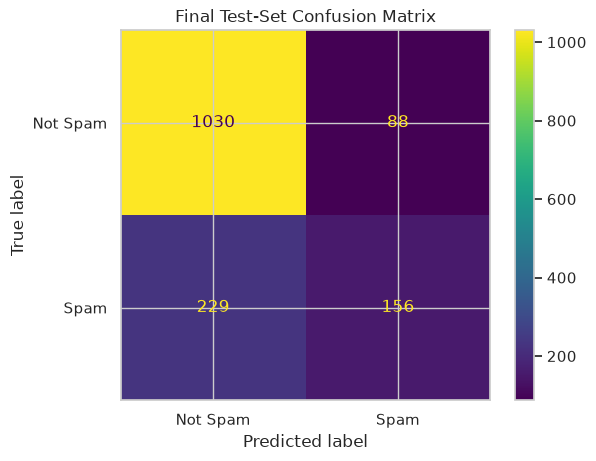

In [49]:
# Create the final test confusion matrix

final_confusion_matrix = confusion_matrix(y_test, y_test_predicted)

display = ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=[
        "Not Spam",
        "Spam"
    ]
)

# Display the confusion matrix
display.plot()

plt.title(
    "Final Test-Set Confusion Matrix"
)

plt.show()

In [50]:
# Verification - do not modify

print(
    "Q9 Answer - Predictions match test observations:",
    len(y_test_predicted) == len(y_test)
)

print(
    "All probabilities are valid:",
    (
        (y_test_probability >= 0)
        & (y_test_probability <= 1)
    ).all()
)

print(
    "All test observations represented:",
    final_confusion_matrix.sum()
    == len(y_test)
)

Q9 Answer - Predictions match test observations: True
All probabilities are valid: True
All test observations represented: True


**Your answer:** The final test is slightly better than the previous models with a F1 score of 0.496 (previous higher F1 score was 0.466). The precision of our model is better than a coin flip and is equivalent to our highest precision during testing (0.639 vs 0.665). But still has trouble identifying spam as spam (recall of 0.405) and seen in the confusion matrix. This means that the model will be decent at keeping non-spam email in the mailbox but will still struggle at keeping spam away. In future work, the classifier could probably incorporate unsupervised learning techniques to find some previously unknown spam patterns.